In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
data=pd.read_csv('/content/Housing.csv')
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
data.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [4]:
data['total_bedrooms']=data['total_bedrooms'].fillna(data['total_bedrooms'].mean())

<Axes: >

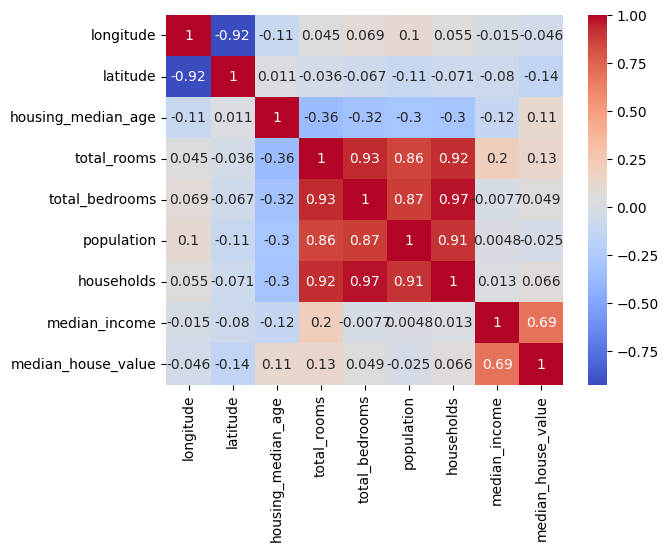

In [5]:
sns.heatmap(data.corr(numeric_only=True),cmap='coolwarm',annot=True)


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20640 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [7]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
data['ocean_proximity']=le.fit_transform(data['ocean_proximity'])

In [8]:
x=data.drop('median_house_value',axis=1)
y=data['median_house_value']

In [9]:
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.2,random_state=42)


In [12]:
sc=StandardScaler()
xtrain_scaled=sc.fit_transform(xtrain)
xtest_scaled=sc.transform(xtest)

In [13]:
linear=LinearRegression()
rid=Ridge()
lasso=Lasso()

In [14]:
linear.fit(xtrain_scaled,ytrain)


LinearRegression()

In [15]:
ridge_param={'alpha':[0.001,0.01,0.1,1,10,100]}
lasso_param={'alpha':[0.001,0.01,0.1,1,10,100]}


In [16]:
ridge=GridSearchCV(rid,param_grid=ridge_param,cv=5)
lasso=GridSearchCV(lasso,param_grid=lasso_param,cv=5)

In [17]:
ridge.fit(xtrain_scaled,ytrain)
lasso.fit(xtrain_scaled,ytrain)

GridSearchCV(cv=5, estimator=Lasso(),
             param_grid={'alpha': [0.001, 0.01, 0.1, 1, 10, 100]})

In [18]:
linear_pred=linear.predict(xtest_scaled)
ridge_pred=ridge.best_estimator_.predict(xtest_scaled)
lasso_pred=lasso.best_estimator_.predict(xtest_scaled)

In [19]:
def evaluate(name,ytest,ypred):
  mse=mean_squared_error(ytest,ypred)
  rmse=np.sqrt(mse)
  r2=r2_score(ytest,ypred)
  print(f'{name} results')
  print(f'mse:{mse}')
  print(f'rmse:{rmse}')
  print(f'r2:{r2}')

In [20]:
evaluate('linear',ytest,linear_pred)
evaluate('ridge',ytest,ridge_pred)
evaluate('lasso',ytest,lasso_pred)

linear results
mse:5055025116.165613
rmse:71098.69982050033
r2:0.6142406531011786
ridge results
mse:5050126954.365495
rmse:71064.24525994415
r2:0.6146144418863175
lasso results
mse:5054098843.022044
rmse:71092.18552711714
r2:0.6143113389068278


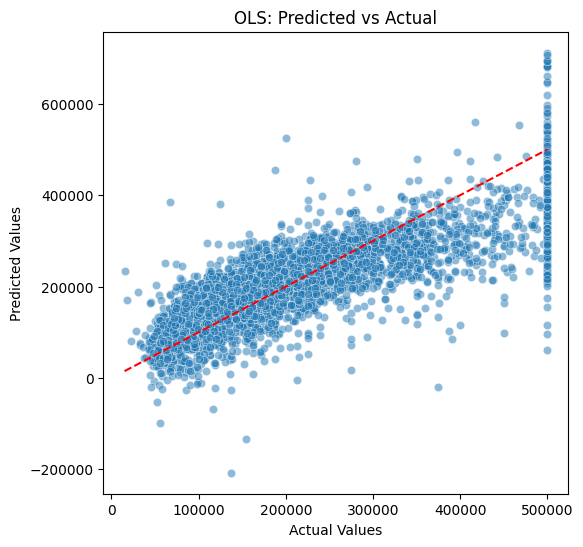

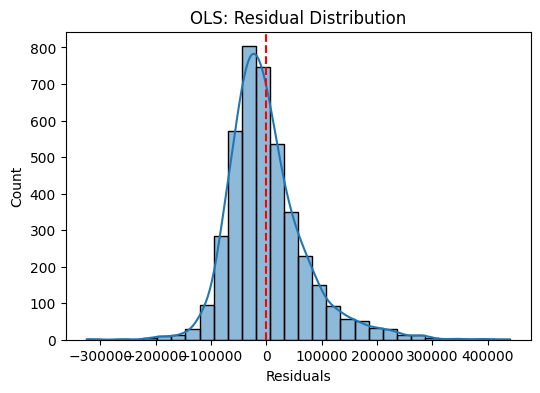

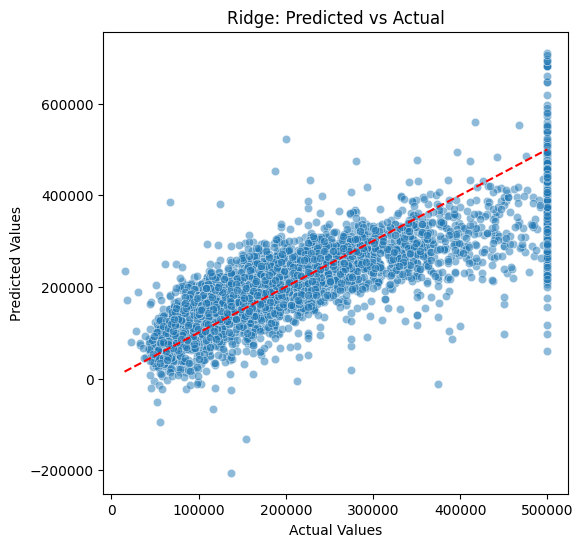

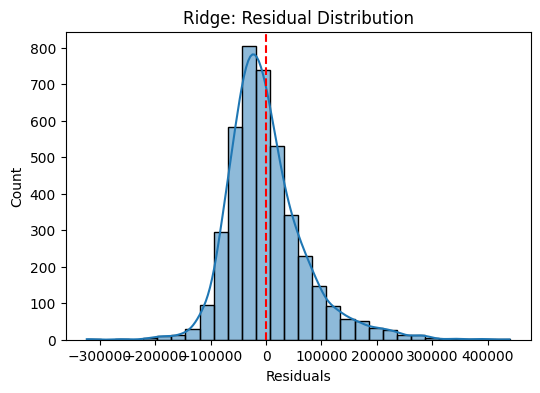

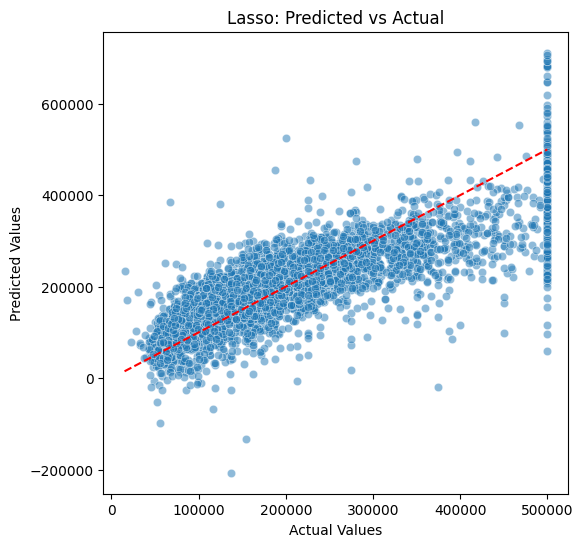

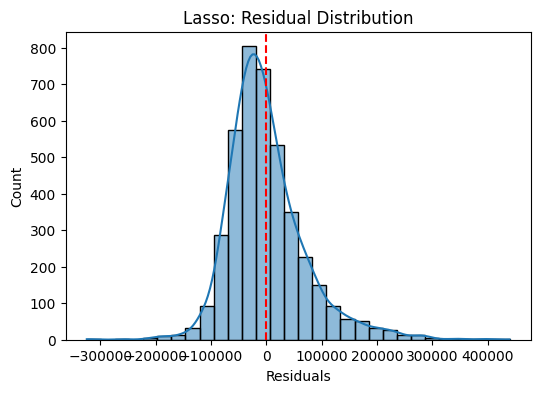

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Function to plot Predicted vs Actual
def plot_predicted_vs_actual(y_true, y_pred, model_name):
    plt.figure(figsize=(6,6))
    sns.scatterplot(x=y_true, y=y_pred, alpha=0.5)
    plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--')  # perfect fit line
    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.title(f"{model_name}: Predicted vs Actual")
    plt.show()

# Function to plot Residuals
def plot_residuals(y_true, y_pred, model_name):
    residuals = y_true - y_pred
    plt.figure(figsize=(6,4))
    sns.histplot(residuals, bins=30, kde=True)
    plt.axvline(0, color='red', linestyle='--')
    plt.xlabel("Residuals")
    plt.title(f"{model_name}: Residual Distribution")
    plt.show()

# Example usage for each model
plot_predicted_vs_actual(ytest, linear_pred, "OLS")
plot_residuals(ytest, linear_pred, "OLS")

plot_predicted_vs_actual(ytest, ridge_pred, "Ridge")
plot_residuals(ytest, ridge_pred, "Ridge")

plot_predicted_vs_actual(ytest, lasso_pred, "Lasso")
plot_residuals(ytest, lasso_pred, "Lasso")
